<center><h1>Детекция объектов

<h2>IOU

<h3>Загрузка данных и дообучение моделий

In [1]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torchvision.utils import draw_bounding_boxes
from PIL import Image
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from tqdm import tqdm
from torchvision.ops import batched_nms

In [ ]:
dataset = datasets.VOCDetection(root='./SimpleNN', image_set='train', download=False)

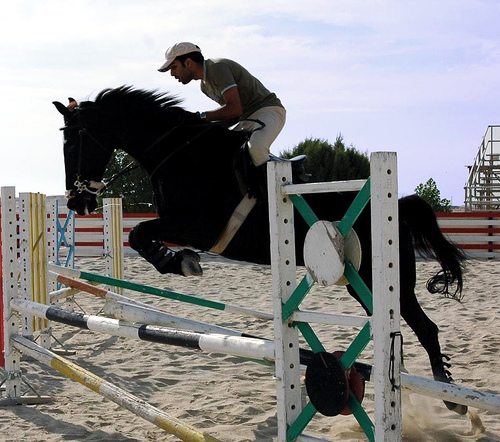

In [3]:
dataset[0][0]

In [4]:
dataset[0][1]

{'annotation': {'folder': 'VOC2012',
  'filename': '2008_000008.jpg',
  'source': {'database': 'The VOC2008 Database',
   'annotation': 'PASCAL VOC2008',
   'image': 'flickr'},
  'size': {'width': '500', 'height': '442', 'depth': '3'},
  'segmented': '0',
  'object': [{'name': 'horse',
    'pose': 'Left',
    'truncated': '0',
    'occluded': '1',
    'bndbox': {'xmin': '53', 'ymin': '87', 'xmax': '471', 'ymax': '420'},
    'difficult': '0'},
   {'name': 'person',
    'pose': 'Unspecified',
    'truncated': '1',
    'occluded': '0',
    'bndbox': {'xmin': '158', 'ymin': '44', 'xmax': '289', 'ymax': '167'},
    'difficult': '0'}]}}

In [5]:
names = []
for sample in dataset:
    names.extend(obj['name'] for obj in sample[1]['annotation']['object'])

names = list(set(names))
names

['chair',
 'sofa',
 'bird',
 'pottedplant',
 'motorbike',
 'boat',
 'person',
 'horse',
 'sheep',
 'train',
 'diningtable',
 'aeroplane',
 'bus',
 'dog',
 'tvmonitor',
 'bottle',
 'cat',
 'cow',
 'bicycle',
 'car']

In [6]:
len(names)

20

In [7]:
# Создаём маппинги
tar2idx = {name: idx for idx, name in enumerate(names)}
idx2tar = {idx: name for idx, name in enumerate(names)}

In [8]:
def target_transform(targets):
    target = {}
    target['boxes'] = torch.tensor([[
        float(x['bndbox']['xmin']),
        float(x['bndbox']['ymin']),
        float(x['bndbox']['xmax']),
        float(x['bndbox']['ymax'])
    ] for x in targets['annotation']['object']], dtype=torch.float32)
    target['labels'] = torch.tensor([tar2idx[x['name']] for x in targets['annotation']['object']], dtype=torch.int32)
    return target

In [9]:
target_transform(dataset[0][1])

{'boxes': tensor([[ 53.,  87., 471., 420.],
         [158.,  44., 289., 167.]]),
 'labels': tensor([7, 6], dtype=torch.int32)}

In [10]:
import numpy as np


def show(images):
    to_pil = transforms.ToPILImage()
    if not isinstance(images, list):
        images = [images]
    fig, axes = plt.subplots(ncols=len(images), squeeze=False, figsize=(20, 10))
    for idx, image in enumerate(images):
        image = image.detach()
        image = to_pil(image)
        axes[0, idx].imshow(np.asarray(image))
        axes[0, idx].set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])

def draw_single_image(image, boxes, labels):
    colours = ['green' for _ in boxes]
    show(draw_bounding_boxes(image, boxes, labels, colors=colours, width=6))

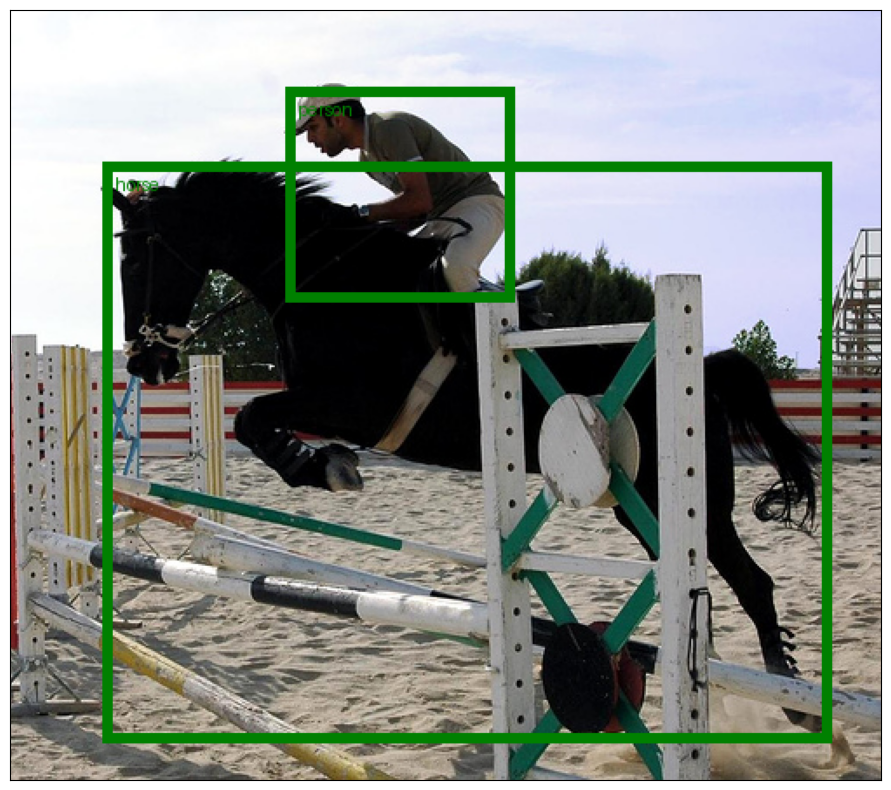

In [11]:
draw_single_image(transforms.PILToTensor()(dataset[0][0]), target_transform(dataset[0][1])['boxes'],
                  [idx2tar[label.item()] for label in target_transform(dataset[0][1])['labels']])

In [12]:
def collate_fn(batch):
    return tuple(zip(*batch))

train_data = datasets.VOCDetection(root='./SimpleNN', image_set='train', transform=transforms.ToTensor(),
                                   target_transform=target_transform)
valid_data = datasets.VOCDetection(root='./SimpleNN', image_set='val', transform=transforms.ToTensor(),
                                   target_transform=target_transform)

In [13]:
# train_loader = DataLoader(train_data, batch_size=8, shuffle=True, pin_memory=True,
#                           num_workers=4, collate_fn=collate_fn)
# valid_loader = DataLoader(valid_data, batch_size=8, shuffle=False, pin_memory=True,
#                           num_workers=4, collate_fn=collate_fn)
train_loader = DataLoader(train_data, batch_size=8, shuffle=True, pin_memory=True,
                          collate_fn=collate_fn)
valid_loader = DataLoader(valid_data, batch_size=8, shuffle=False, pin_memory=True,
                          collate_fn=collate_fn)

In [14]:
model = fasterrcnn_mobilenet_v3_large_fpn(pretrained=True)

d:\MIREA\DPO\.venv3_11_8\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
d:\MIREA\DPO\.venv3_11_8\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_MobileNet_V3_Large_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [15]:
model.roi_heads.box_predictor = FastRCNNPredictor(1024, len(names))

In [16]:
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
model.to(device)

FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): FrozenBatchNorm2d(16, eps=1e-05)
        (2): Hardswish()
      )
      (1): InvertedResidual(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
            (1): FrozenBatchNorm2d(16, eps=1e-05)
            (2): ReLU(inplace=True)
          )
          (1): Conv2dNormActivation(
            (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
            (1): FrozenBatchNorm2d(16, eps=1e-05)
          )
        )
      )
      (2): InvertedResidual(
        (block):

In [17]:
device

'cuda:0'

In [18]:
MAP = MeanAveragePrecision()
optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-4)

In [19]:
print(sum(p.numel() for p in model.parameters()))

19022479


In [20]:
EPOCHS = 5
for epoch in range(EPOCHS):
    model.train()
    for data, targets in tqdm(train_loader, desc='TRAIN'):
        data = list(_.to(device).float() for _ in data)
        targets = [{k: v.to(device).type(torch.int64) for k, v in t.items()} for t in targets]
        y_pred = model(data, targets)
        loss = sum(value for value in y_pred.values())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    with torch.inference_mode():
        model.eval()
        for data, targets in tqdm(valid_loader, desc='VAL'):
            data = list(_.to(device).float() for _ in data)
            y_pred = model(data)
            y_pred = [{k: v.cpu() for k, v in t.items()} for t in y_pred]
            MAP.update(y_pred, targets)
    
print(MAP.compute()['map'])

VAL: 100%|██████████| 728/728 [06:00<00:00,  2.02it/s]


tensor(0.3992)


In [26]:
def apply_nms(orig_prediction, iou_thresh=.1):
    keep = batched_nms(orig_prediction['boxes'], orig_prediction['scores'],
                       orig_prediction['labels'], iou_thresh)
    final_prediciton = orig_prediction

    final_prediciton['boxes'] = final_prediciton['boxes'][keep]
    final_prediciton['scores'] = final_prediciton['scores'][keep]
    final_prediciton['labels'] = final_prediciton['labels'][keep]

    return final_prediciton

@torch.inference_mode()
def vizualize(model, batch):
    model.eval()
    to_pil = transforms.ToPILImage()
    to_tensor = transforms.ToTensor()
    xs, ys = batch
    for i, (x, y) in enumerate(zip(xs, ys)):
        pred = {k: v for k, v in model([x.to(device)])[0].items()}
        pred = apply_nms(pred)
        x = to_tensor(to_pil(x.cpu()))
        true_boxes = draw_bounding_boxes(x, boxes=y['boxes'], 
                                         labels=[idx2tar[label.item()] for label in y['labels']], 
                                         width=5, colors='red')
        predicted_boxes = draw_bounding_boxes(x, boxes=pred['boxes'], 
                                              labels=[idx2tar[label.item()] for label in pred['labels']], 
                                              width=5, colors='blue')
        fig, ax = plt.subplots(1, 2, figsize=(20, 10), facecolor='white')
        ax[0].imshow(to_pil(true_boxes))
        ax[1].imshow(to_pil(predicted_boxes))
        ax[0].axis('off')
        ax[1].axis('off')
        ax[0].set_title('Target boxes')
        ax[1].set_title('Predicted boxes')
        plt.subplots_adjust(wspace=0, hspace=.1)
        plt.show()
        if (i >= 9): break



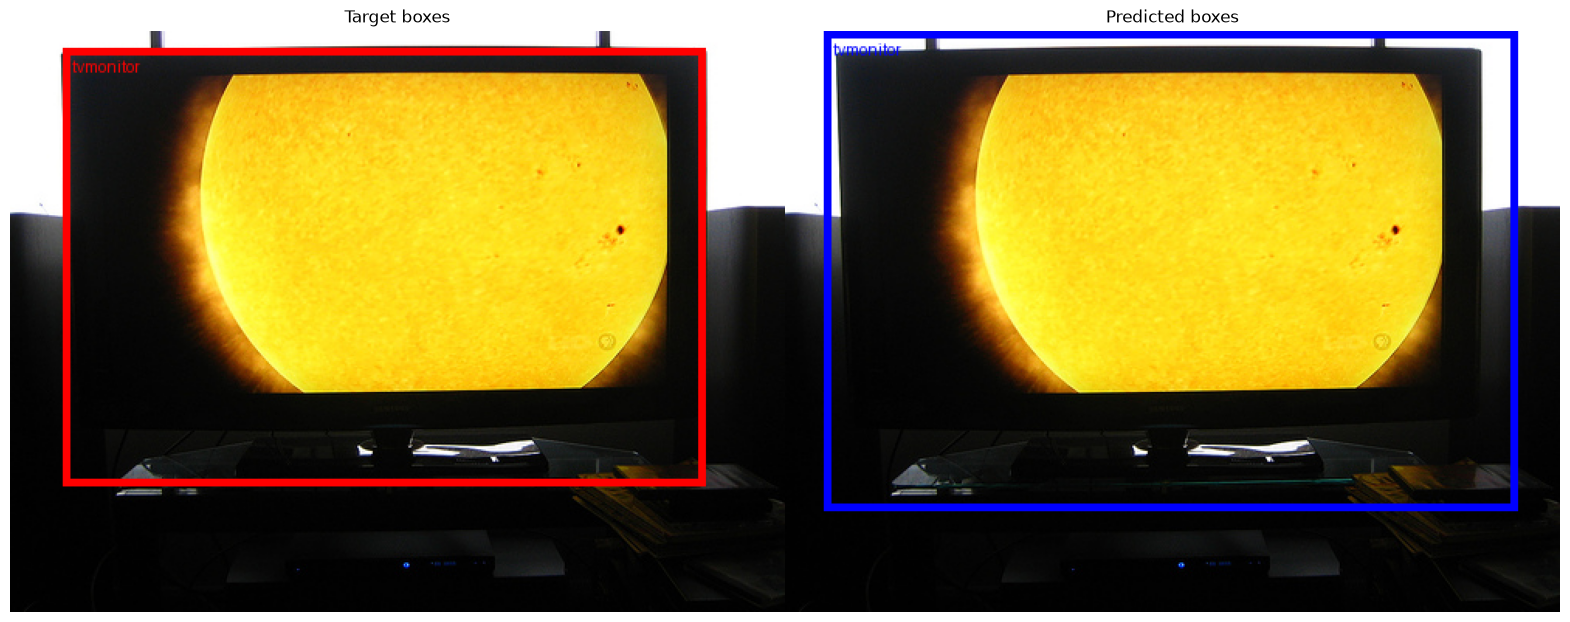

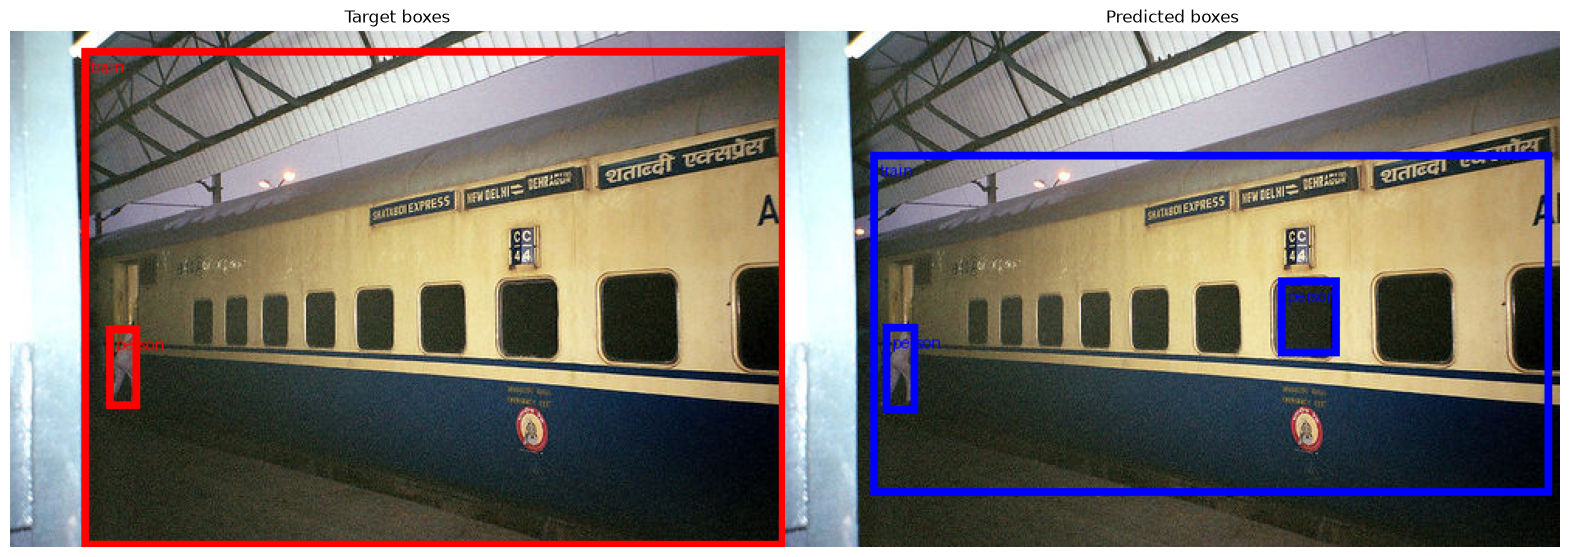

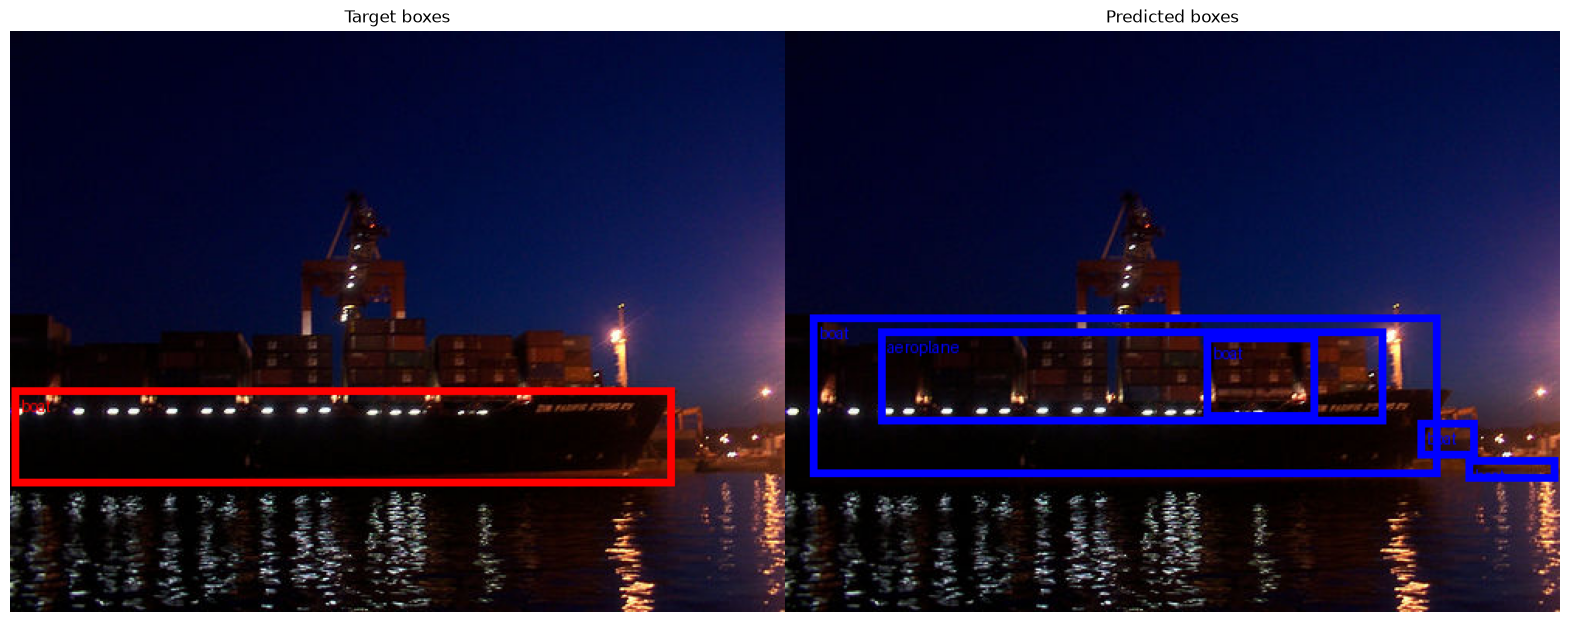

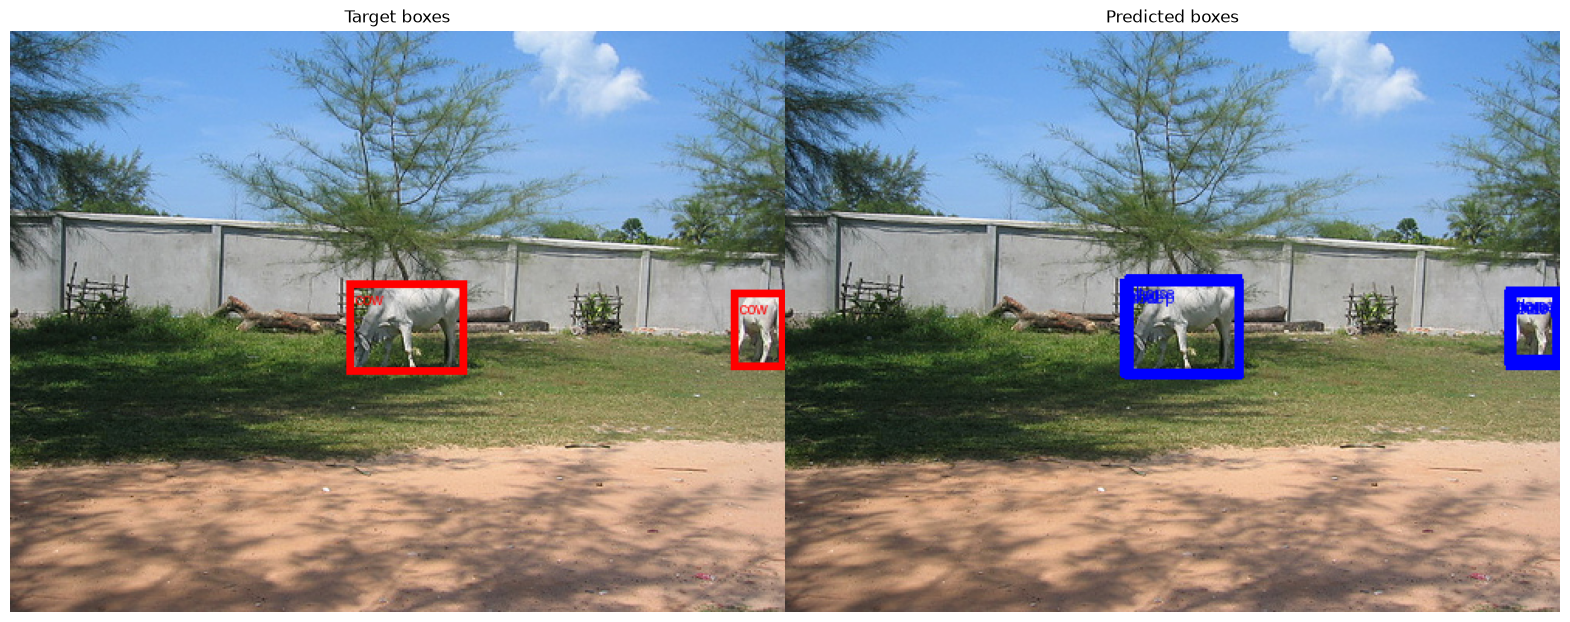

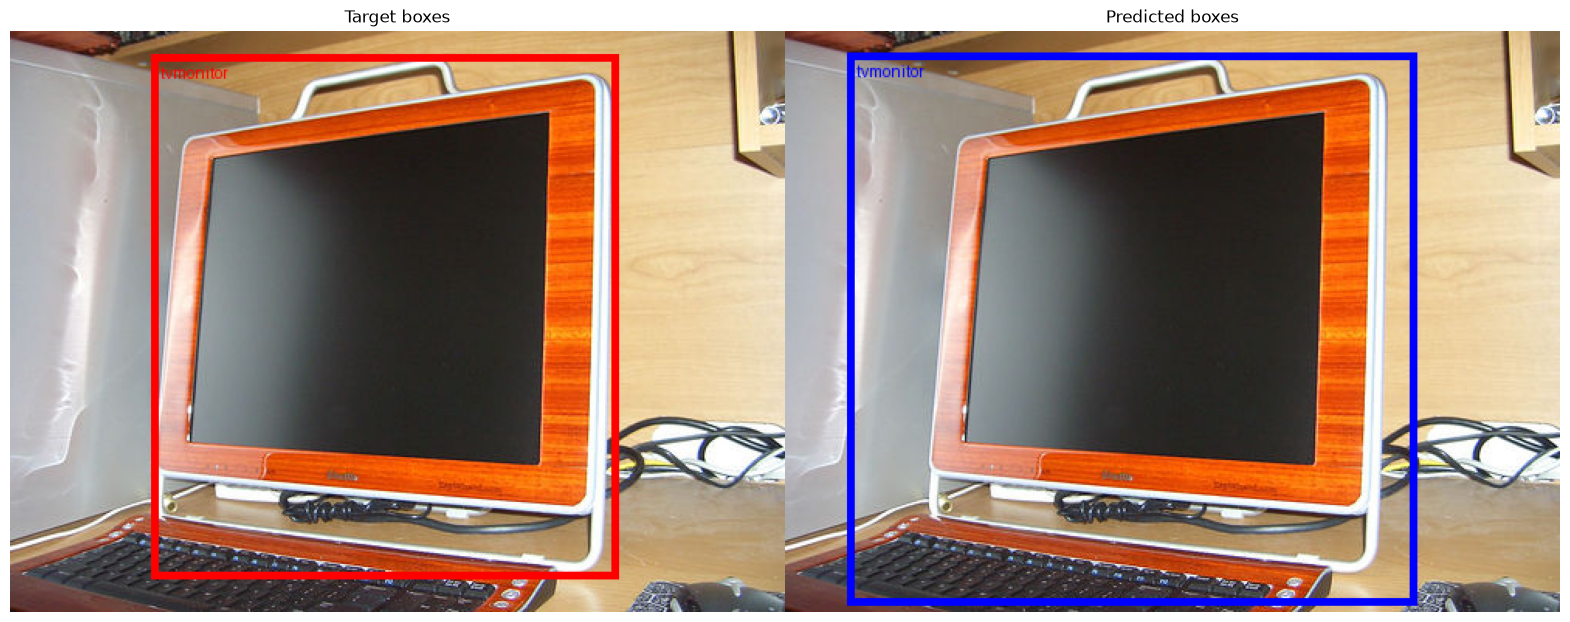

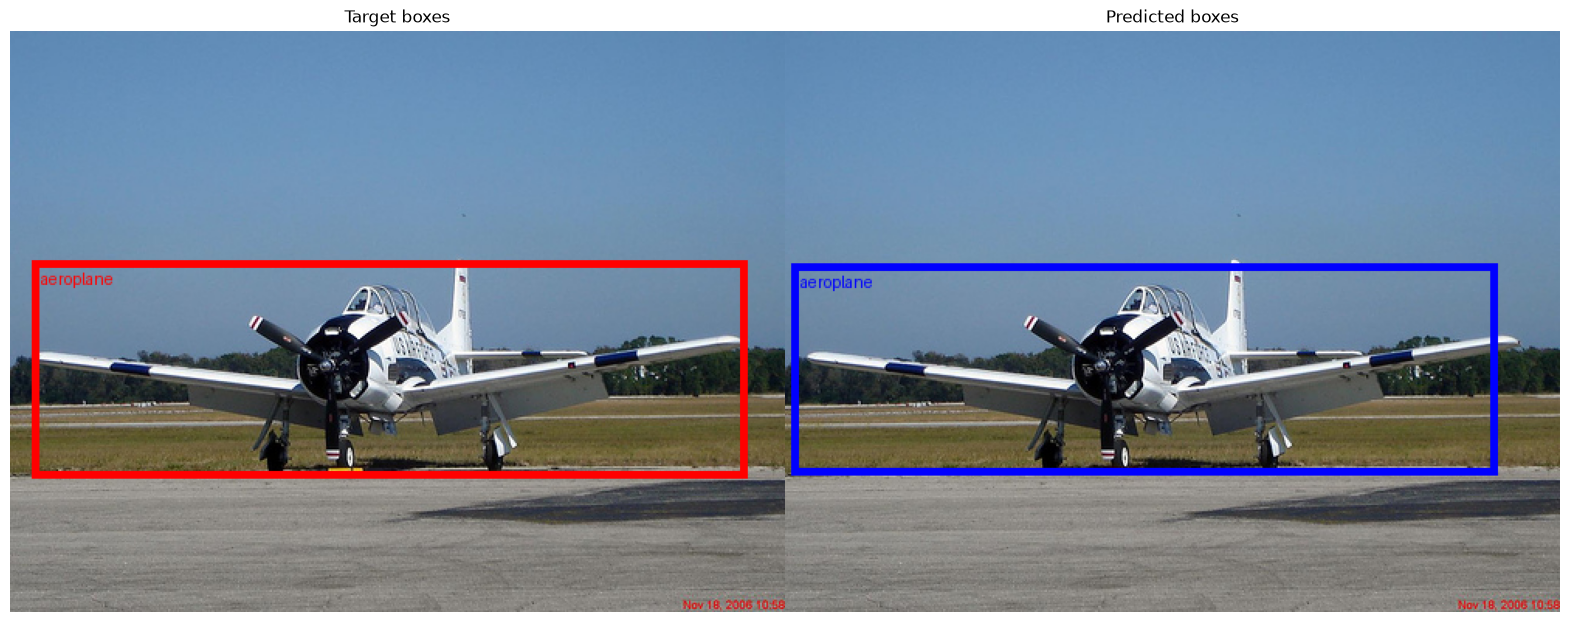

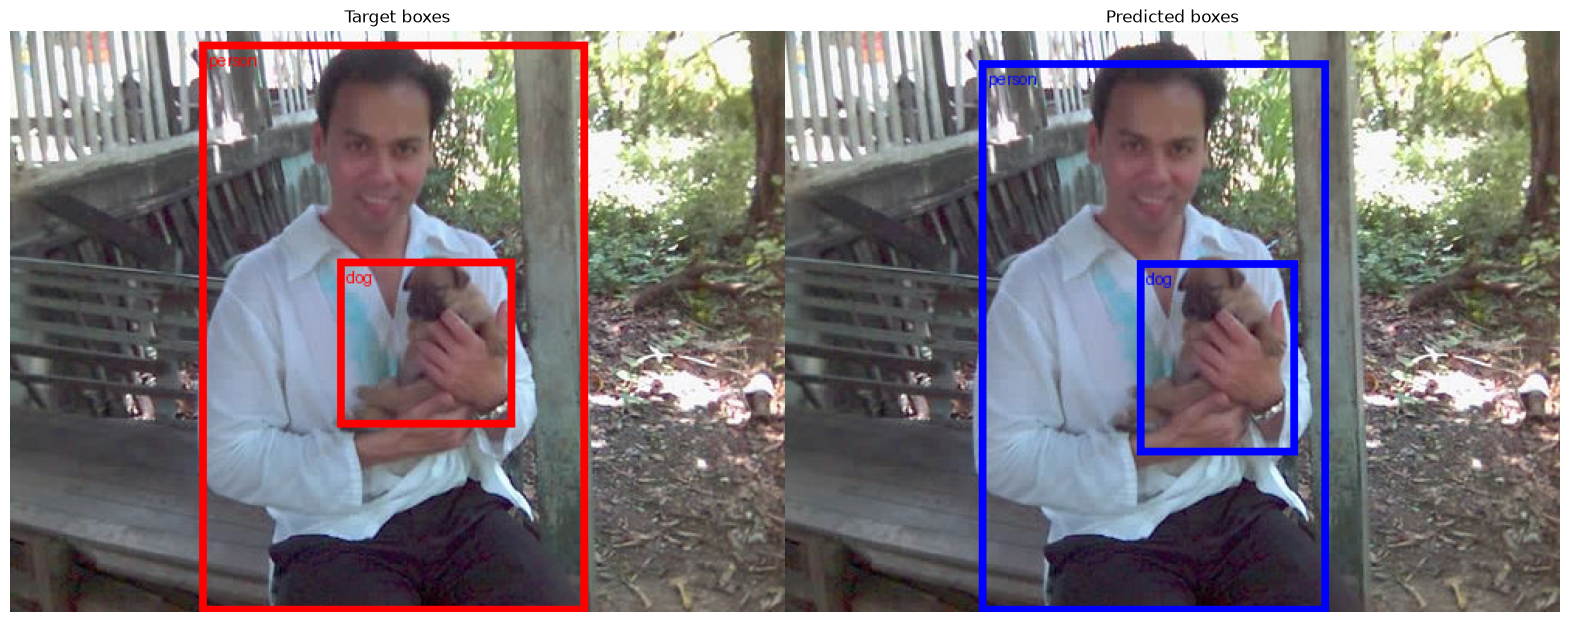

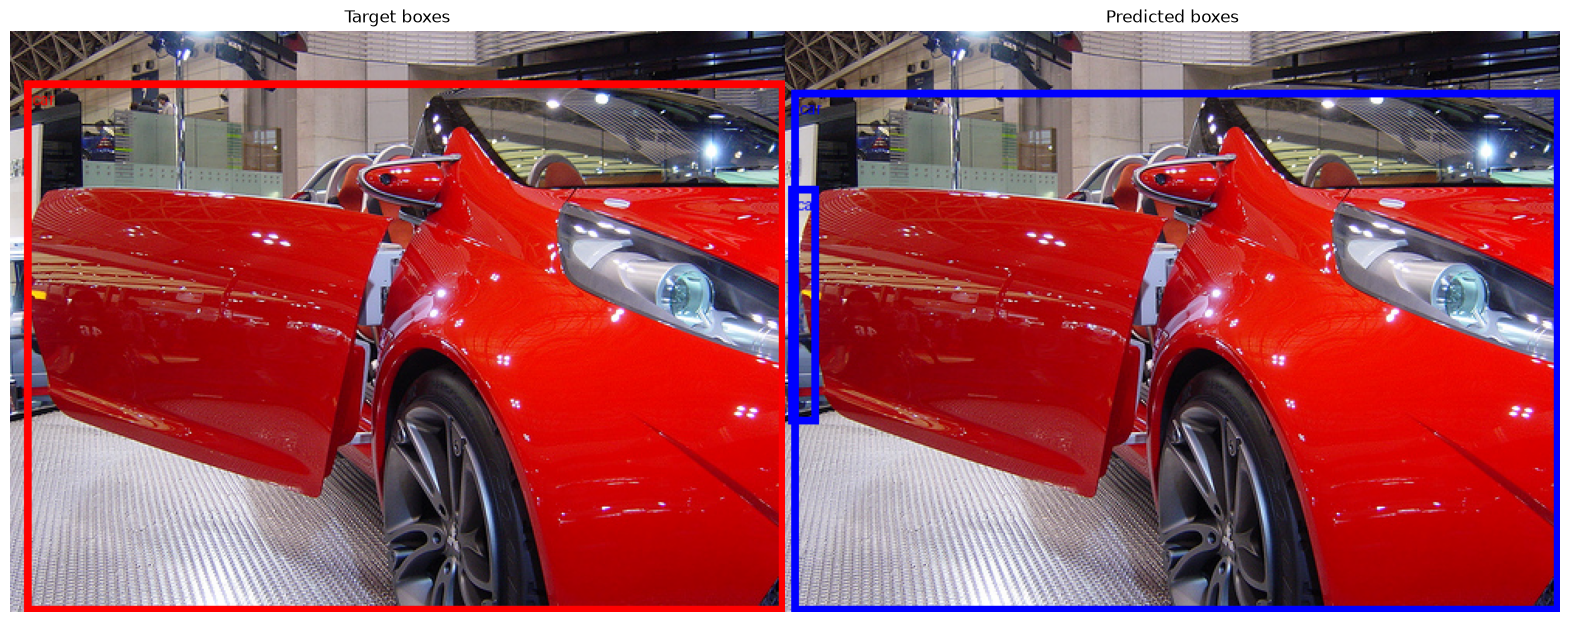

In [28]:
dataiter = iter(valid_loader)
data, targets = next(dataiter)
vizualize(model, (data, targets))

<center><h1>Практическое задание</h1></center>
 
1. Выбрать набор данных для детекции объектов
2. Попробовать различные архитектуры модели, как и разные backbone, так и SSD
3. Сделать наложение реальных и предсказанных объектов одновременно, отделив их различными цветами
4. Замерить IoU на малой выборке изображений